In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

In [ ]:
# Evaluated models
bert_models = [
    "distilbert-base-spanish-uncased",
    "roberta-large-bne",
    "mdeberta-v3-base"
    # "longformer-base-4096"
]
open_source_llms = [
    "llama-3.1-8b",
    "gpt-oss-20b",
    "deepseek-chat"
]
proprietary_llms = [
    "gpt-5.2",
    "gpt-5-mini",
    "claude-sonnet-4-6",
    "claude-haiku-4.5",
    "gemini-3.1-pro-preview",
    "gemini-3-flash-preview"
]

llm_models = open_source_llms + proprietary_llms
models = bert_models + llm_models

tasks = ["anx", "dep", "ed", "multi"]

# Read metrics tables

In [ ]:
# Connect Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
base = "/content/drive/MyDrive/tfg/corpusMentalRiskES/resultados/"
CACHE_DIR = base + "metricas"

# Read data and tables generated in 5_1_metrics.ipynb
data = pd.read_parquet(f"{CACHE_DIR}/all_predictions.parquet")
metricas_anx = pd.read_csv(f"{CACHE_DIR}/metricas_anx.csv", index_col="model")
metricas_dep = pd.read_csv(f"{CACHE_DIR}/metricas_dep.csv", index_col="model")
metricas_ed = pd.read_csv(f"{CACHE_DIR}/metricas_ed.csv", index_col="model")
metricas_multi = pd.read_csv(f"{CACHE_DIR}/metricas_multi.csv", index_col="model")

In [ ]:
data.tail()

,sample_id,user_id,model,task,y_true,y_pred
4811,subject68_ed,subject68,gemini-3-flash-preview,multi,3,3
4812,subject8_ed,subject8,gemini-3-flash-preview,multi,3,3
4813,subject83_ed,subject83,gemini-3-flash-preview,multi,0,2
4814,subject95_ed,subject95,gemini-3-flash-preview,multi,3,3
4815,subject97_ed,subject97,gemini-3-flash-preview,multi,3,3


# Confusion Matrices

In [ ]:
def plot_confusion_matrices_grid(df, models, task, normalize=True, n_cols=3):
    """
    Generates a grid of confusion matrices for all evaluated models
    in a specific task.

    Can be applied to both binary and multiclass classification

    If normalize=True, each row is normalized to show percentages
    instead of absolute frequencies.

    Additionally, the number of subjects (n) of each true class is indicated
    to facilitate the interpretation of percentages.
    """

    # =========================================================
    # Define labels according to task type
    # =========================================================
    if task == "multi":
        # Multiclase
        labels = [0, 1, 2, 3]
        class_labels = ["Control", "Anx", "Dep", "ED"]
    else:
        # Binaria
        labels = [0, 1]
        class_labels = ["Control", "Suffer"]

    # =========================================================
    # Chart grid configuration
    # =========================================================
    n = len(models)
    cols = n_cols
    rows = int(np.ceil(n / cols))

    fig, axes = plt.subplots(rows, cols, figsize=(cols*5, rows*4))
    axes = axes.flatten()

    # =========================================================
    # Generate confusion matrix for each model
    # =========================================================
    for i, model in enumerate(models):
        subset = df[
            (df["model"] == model) &
            (df["task"] == task)
        ]

        y_true = subset["y_true"]
        y_pred = subset["y_pred"]

        # Absolute matrix
        cm_counts = confusion_matrix(y_true, y_pred, labels=labels)

        # Number of real subjects per class
        row_counts = cm_counts.sum(axis=1)

        if normalize:
            row_sums = row_counts.reshape(-1, 1)

            cm = np.divide(
                cm_counts.astype(float),
                row_sums,
                out=np.zeros_like(cm_counts, dtype=float),
                where=row_sums != 0
            )
            cm *= 100

            annot = np.empty_like(cm, dtype=object)

            for r in range(cm.shape[0]):
                for c in range(cm.shape[1]):
                    annot[r, c] = (
                        f"{cm[r, c]:.1f}%\n"
                        f"(n={cm_counts[r, c]})"
                    )
        else:
            cm = cm_counts
            annot = cm.astype(str)

        # =========================================================
        # Plot confusion matrix
        # =========================================================
        show_cbar = (i % cols == cols - 1)

        sns.heatmap(
            cm,
            annot = annot,
            fmt="",
            cmap="Blues",
            xticklabels=class_labels,
            yticklabels=class_labels,
            ax=axes[i],
            cbar=show_cbar,
            annot_kws={"size": 12}
        )

        axes[i].set_title(model, fontsize=16)
        axes[i].set_xlabel("Predicted", fontsize=12)
        axes[i].set_ylabel("True", fontsize=12)
        axes[i].tick_params(axis='both', labelsize=11)

    # remove empty subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    # plt.suptitle(f"Confusion Matrices - {task}", fontsize=16)
    plt.tight_layout()
    plt.show()

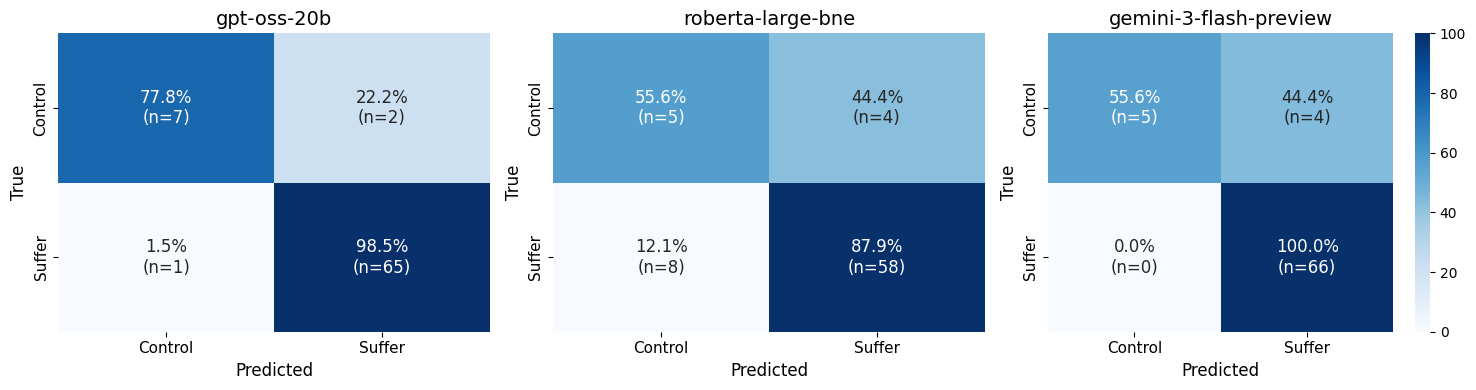

In [ ]:
models_anx = ["gpt-oss-20b", "roberta-large-bne", "gemini-3-flash-preview"]
plot_confusion_matrices_grid(data, models_anx, "anx")

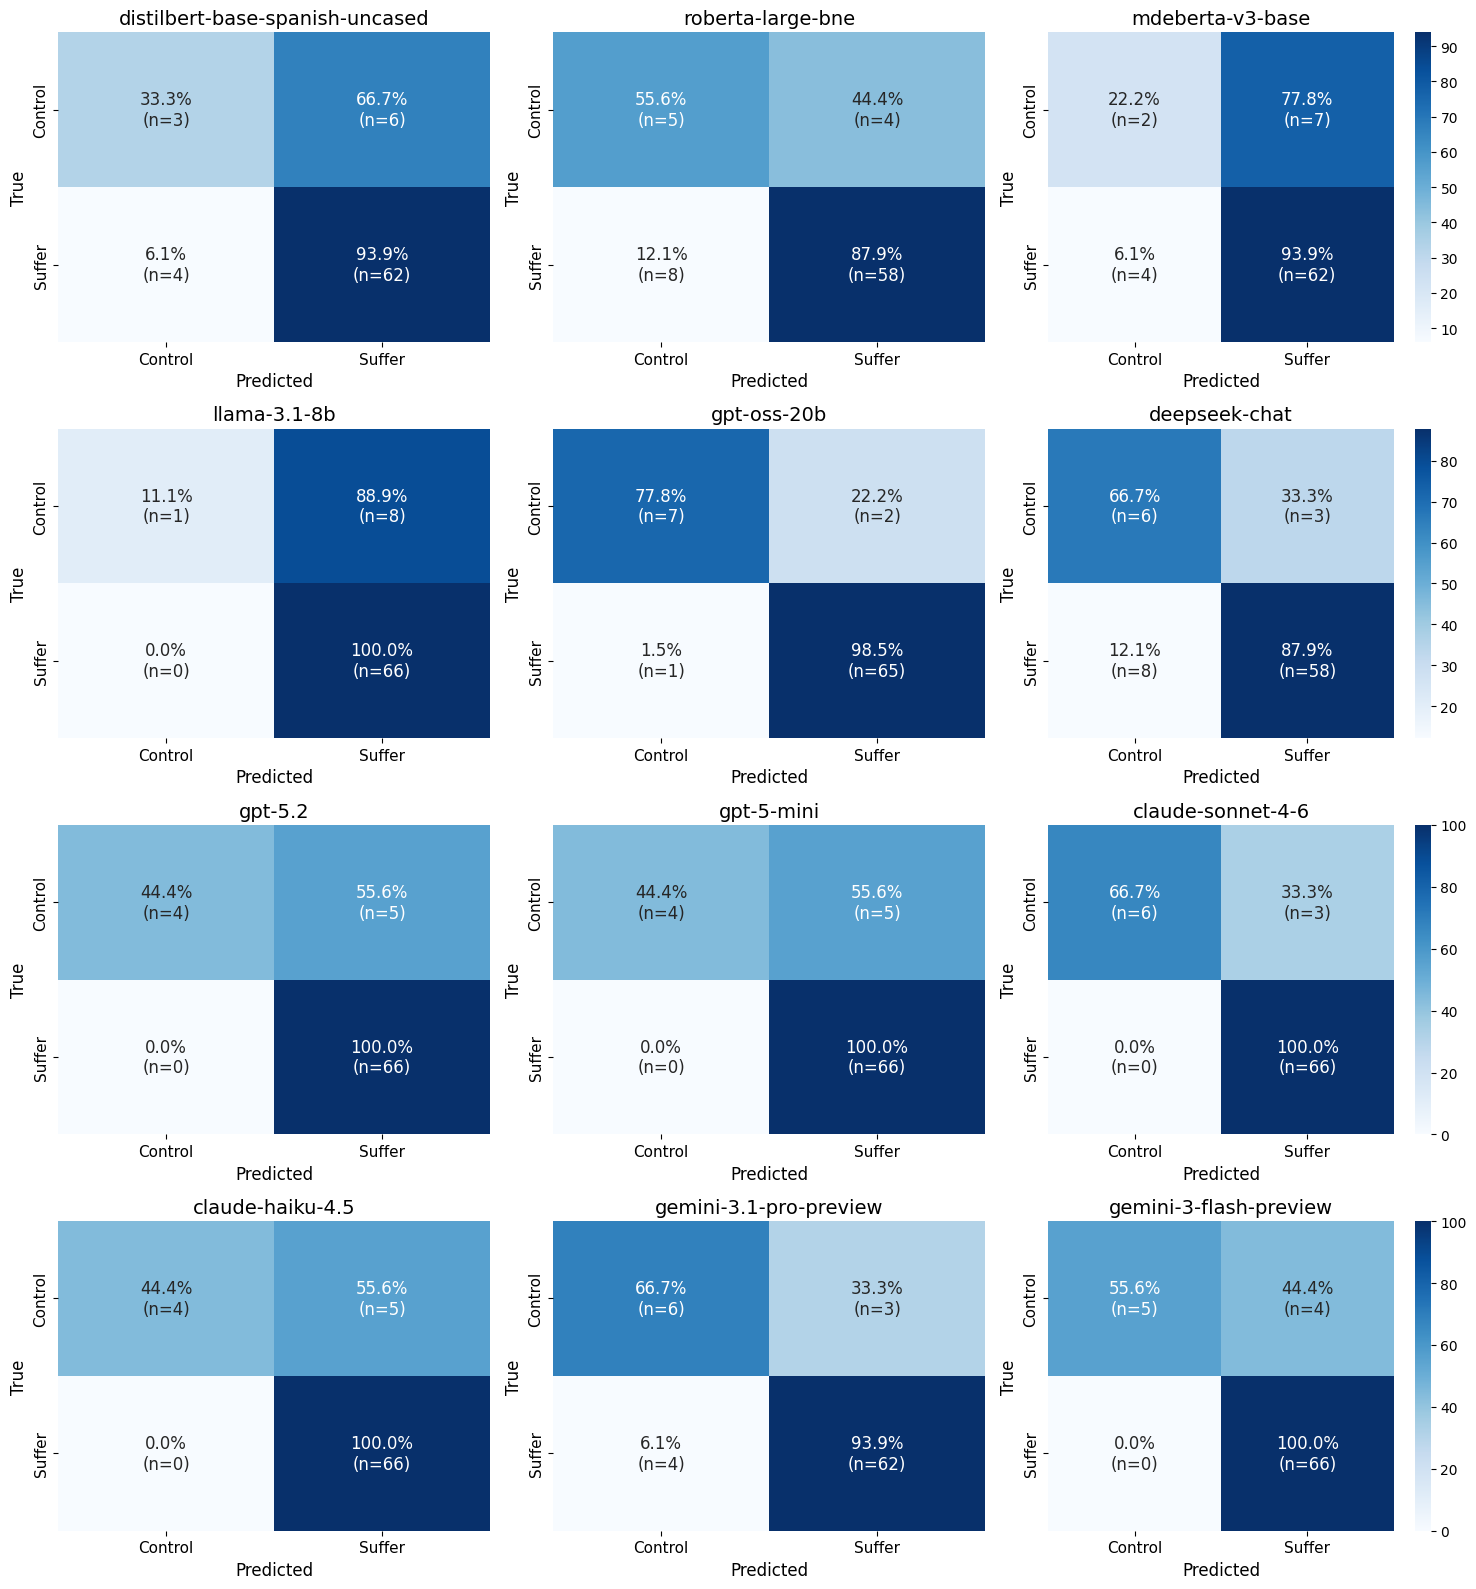

In [ ]:
plot_confusion_matrices_grid(data, models, "anx")

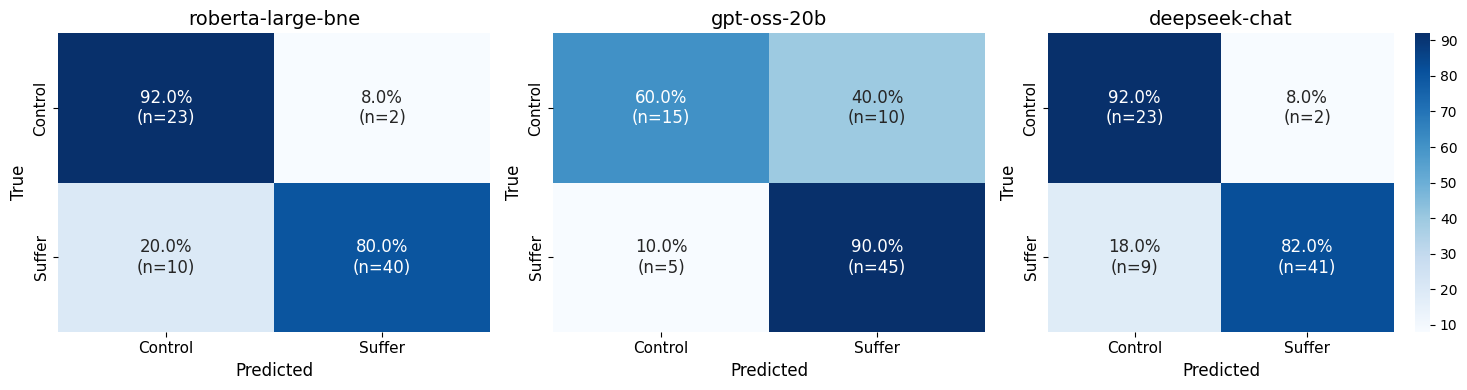

In [ ]:
models_dep = ["roberta-large-bne", "gpt-oss-20b", "deepseek-chat"]
plot_confusion_matrices_grid(data, models_dep, "dep")

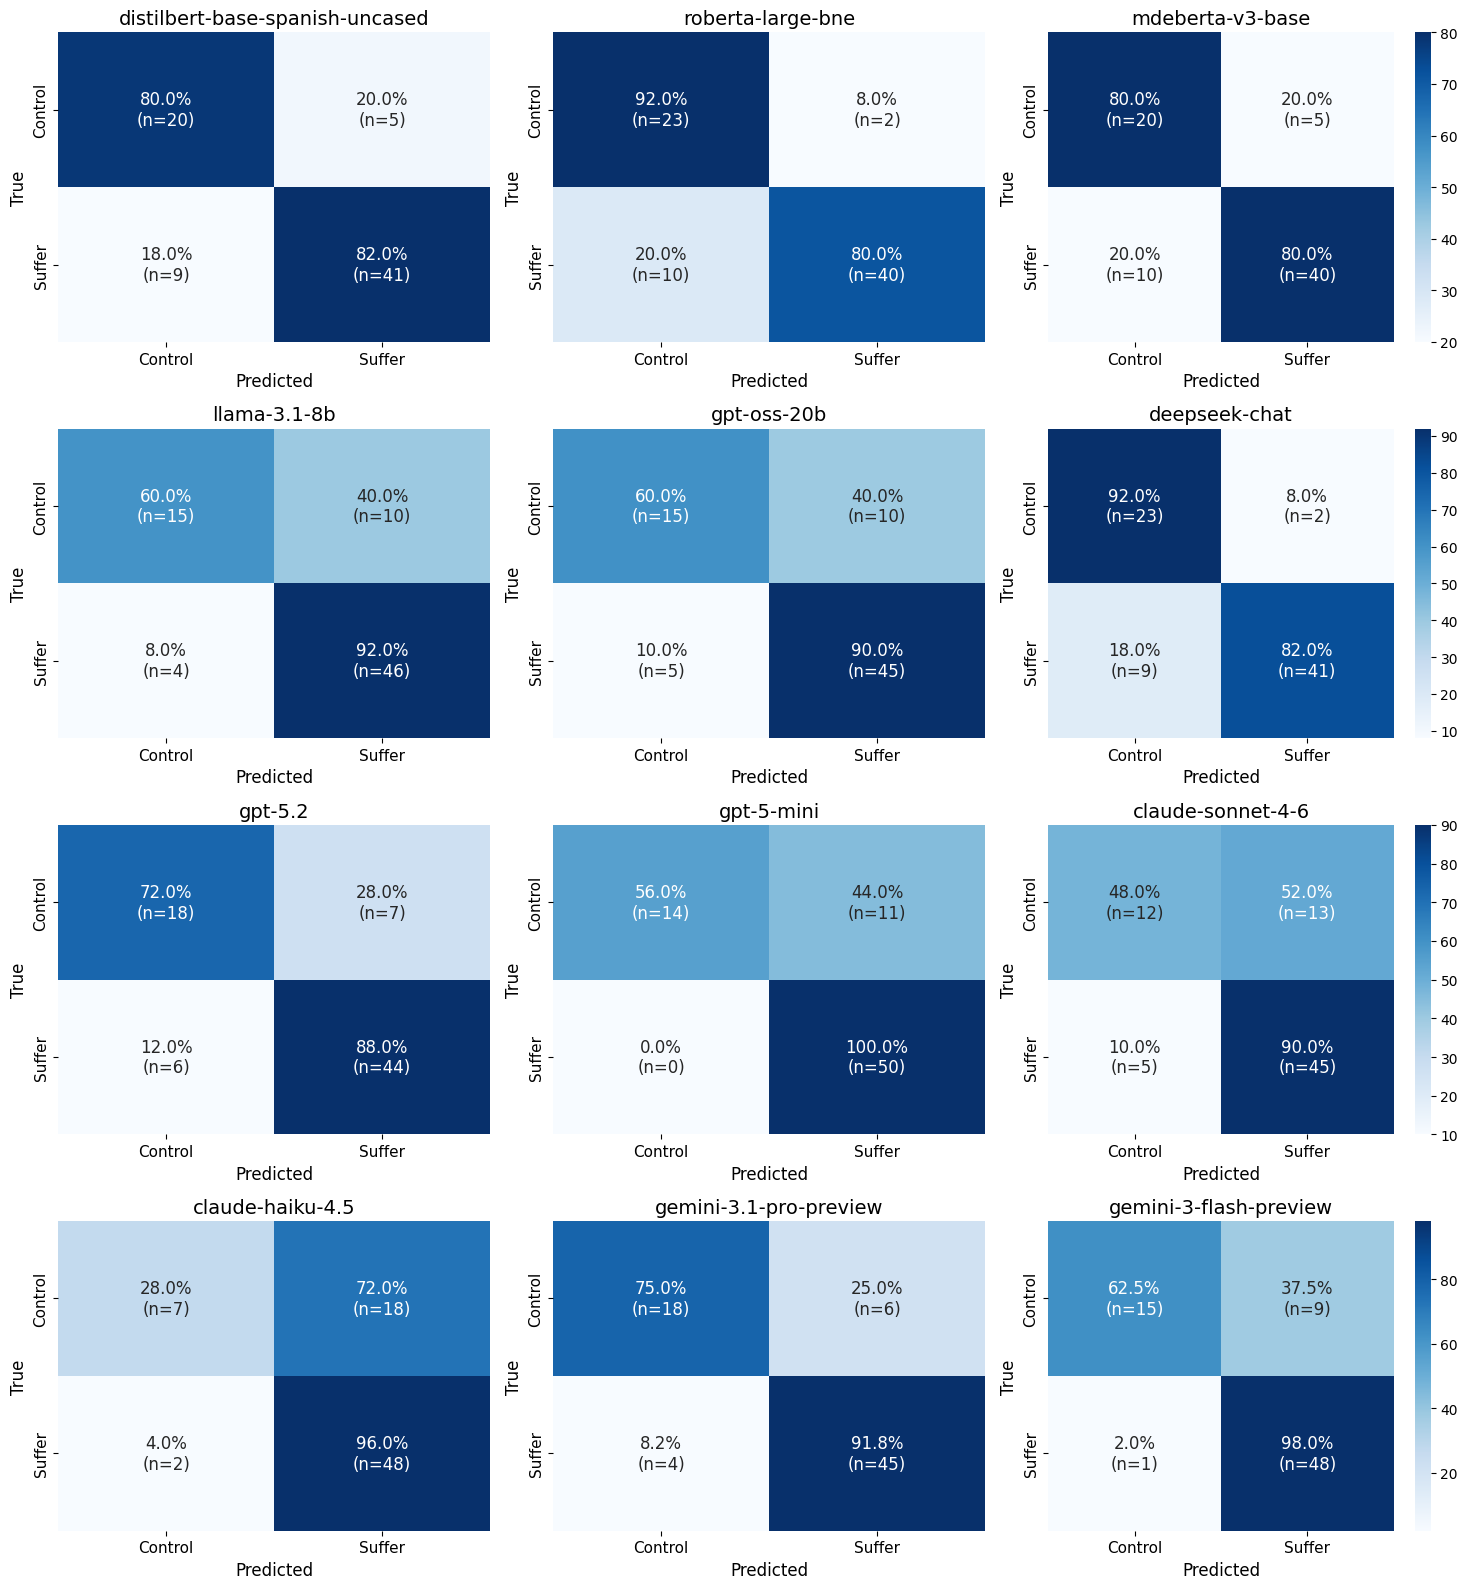

In [ ]:
plot_confusion_matrices_grid(data, models, "dep")

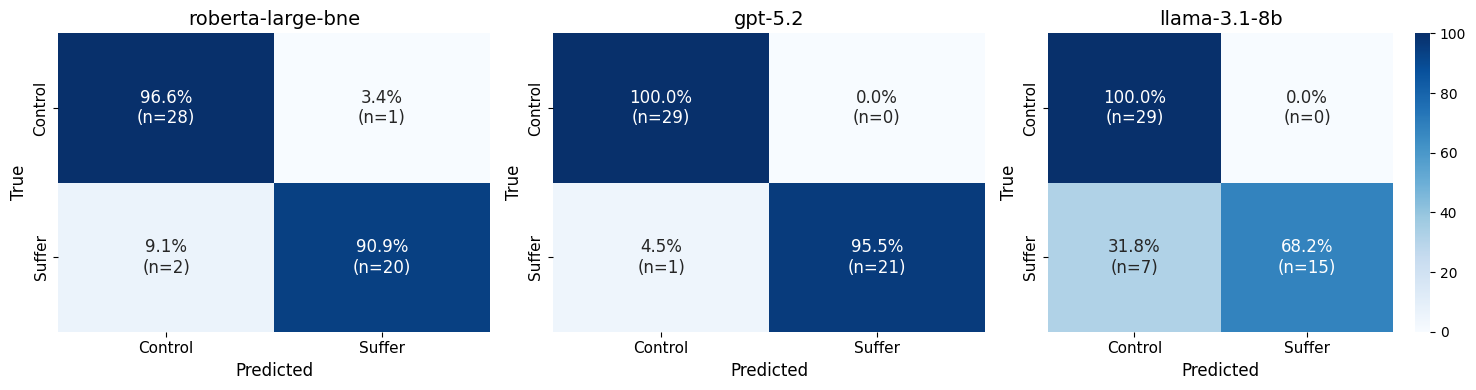

In [ ]:
models_ed = ["roberta-large-bne", "gpt-5.2", "llama-3.1-8b"]
plot_confusion_matrices_grid(data, models_ed, "ed", n_cols=3)

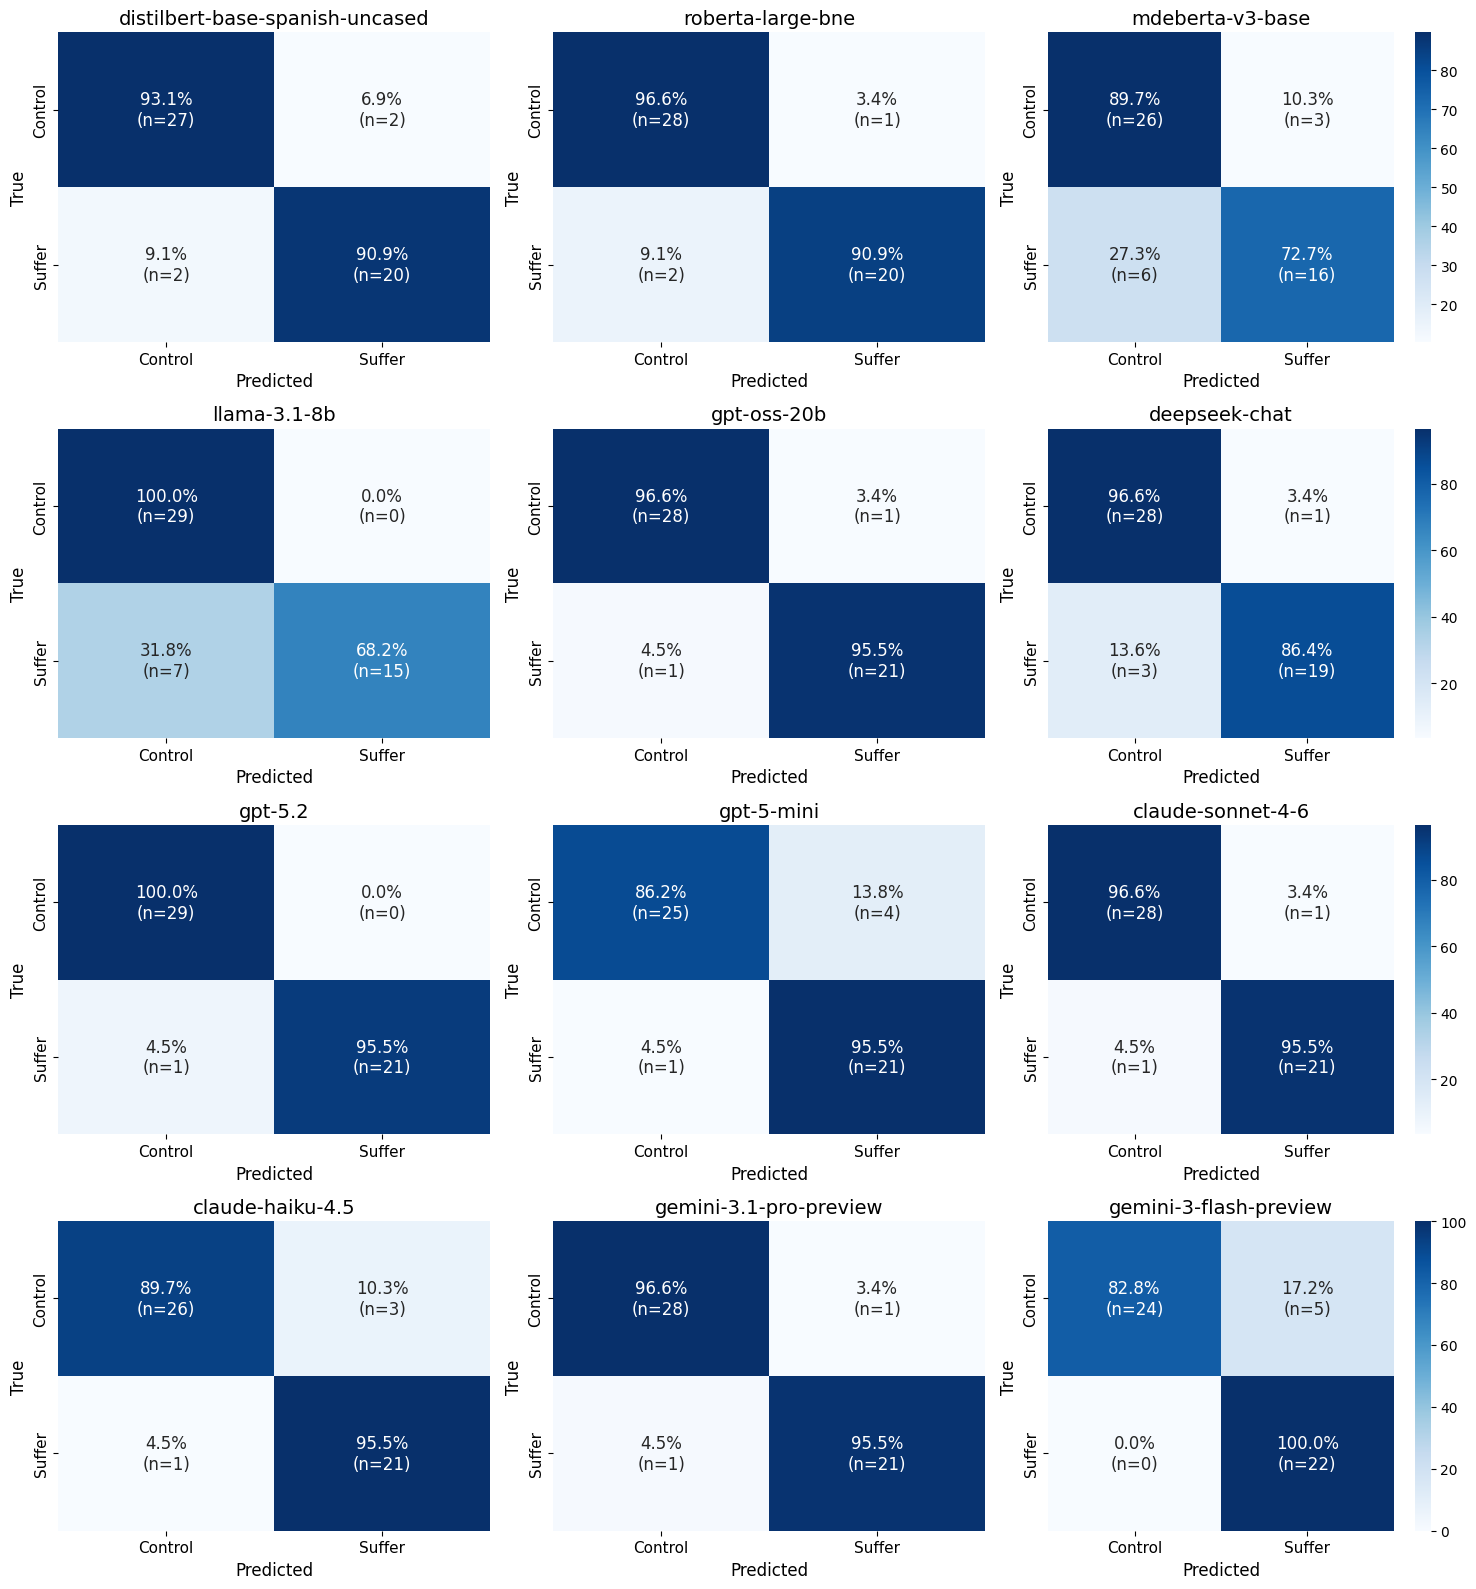

In [ ]:
plot_confusion_matrices_grid(data, models, "ed")

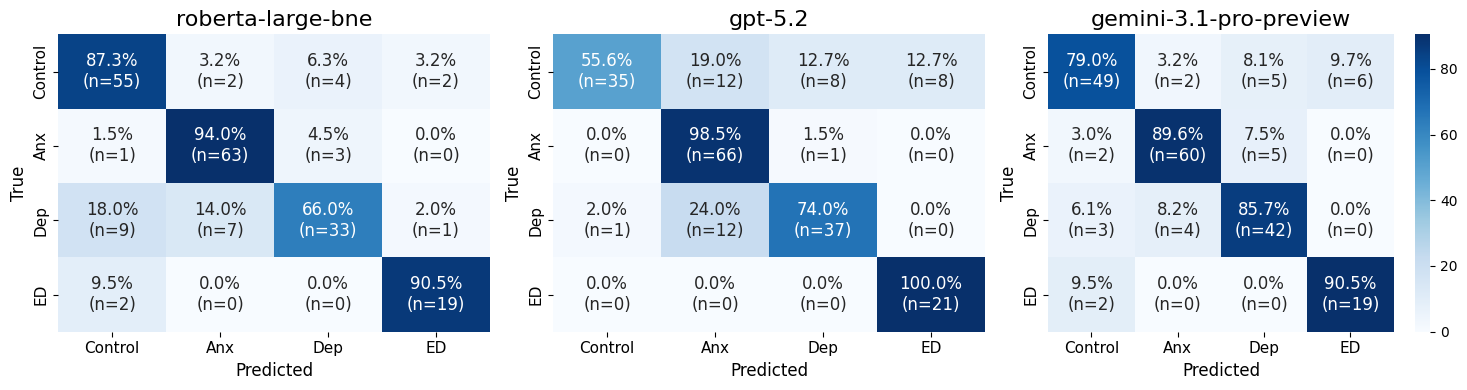

In [ ]:
models_multi = ["roberta-large-bne", "gpt-5.2", "gemini-3.1-pro-preview"]
plot_confusion_matrices_grid(data, models_multi, "multi")

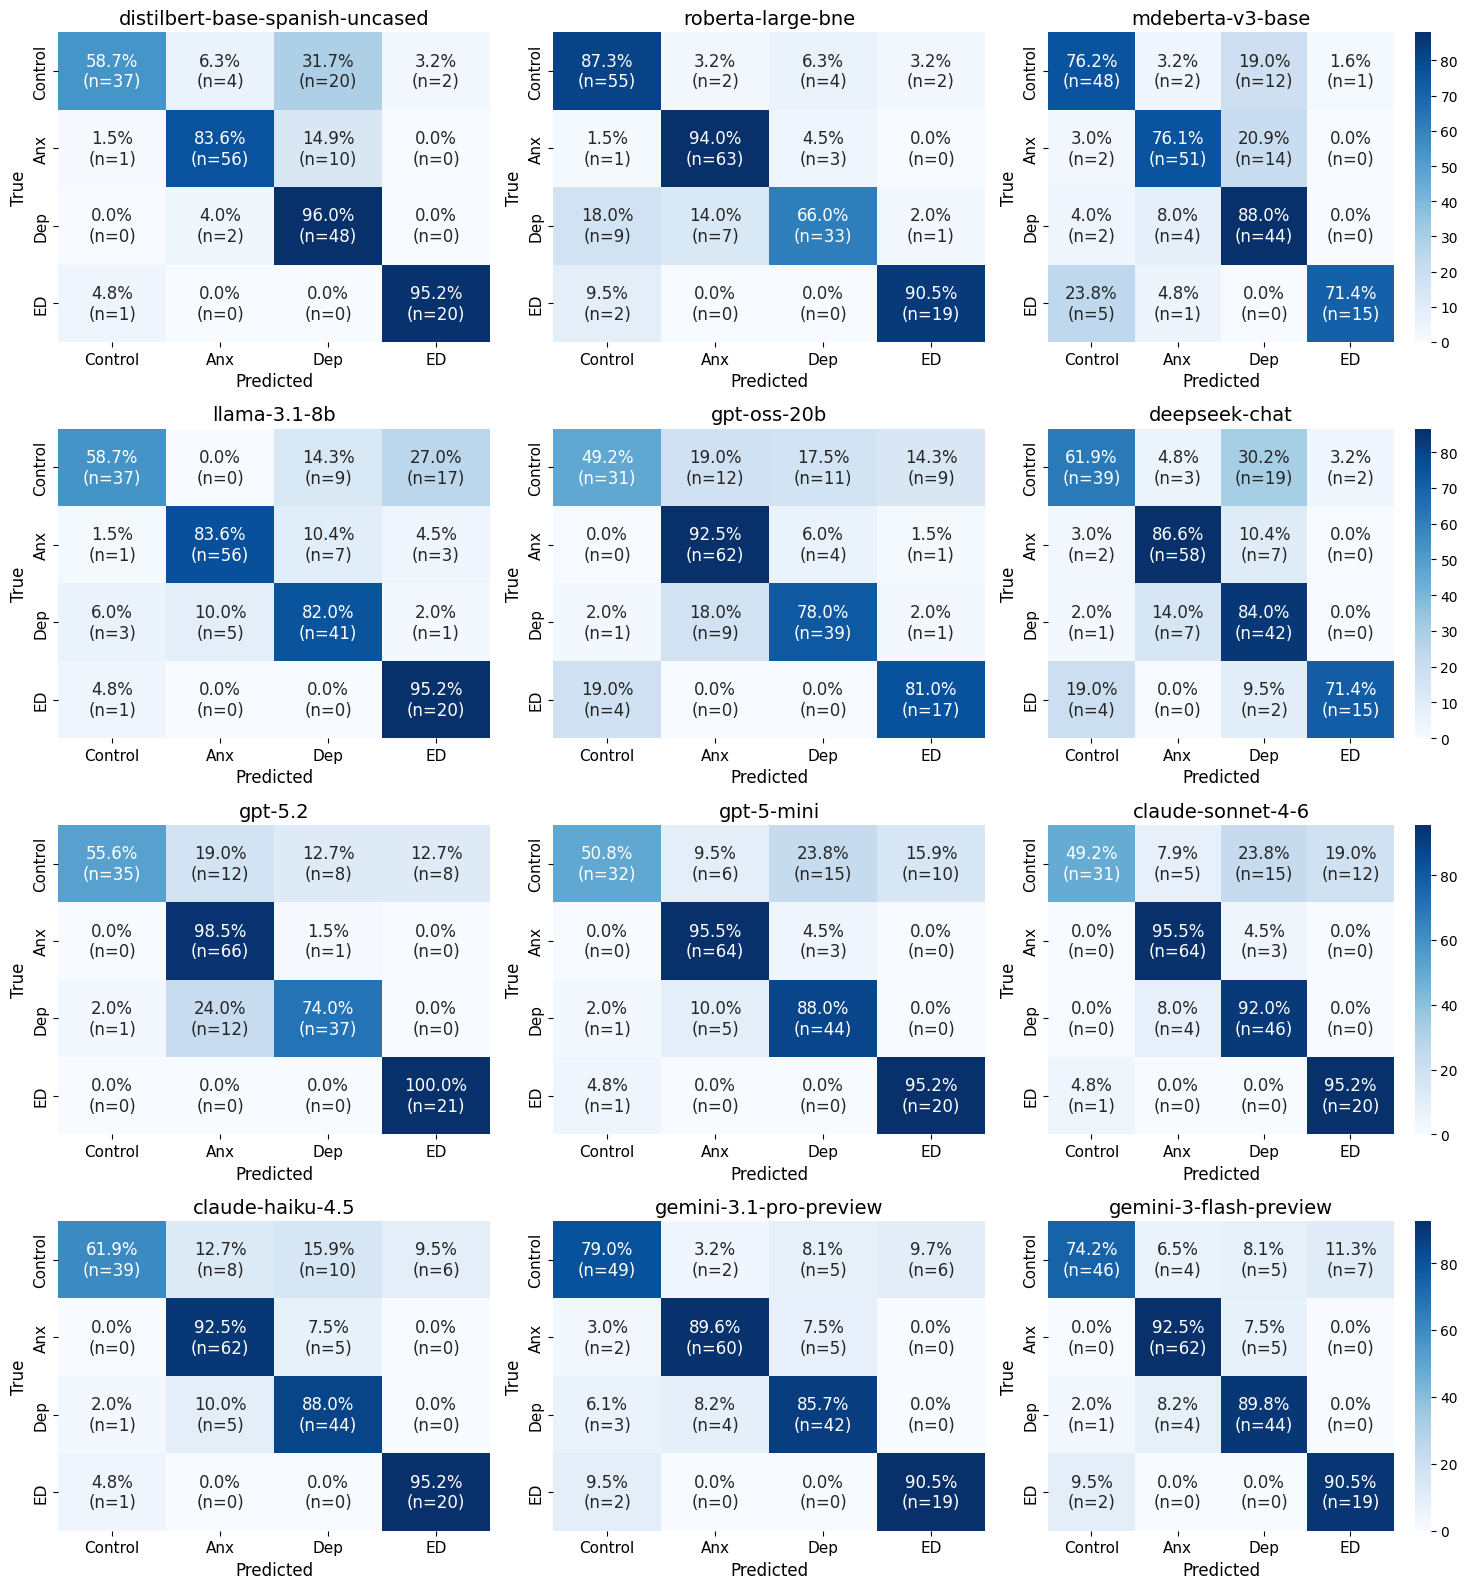

In [ ]:
plot_confusion_matrices_grid(data, models, "multi")